A carry-loss probability is assembled from defender-specific arrival probabilities and a shared survival mass. This toy visualization varies speed and nearest pitch-boundary distance using the solver’s actual intensity form. **own derivation**

## Model and inputs

The solver evaluates every defender’s arrival CDF at the carrier’s extrapolated position x_bc(t)=x_bc(0)+v_bc t. For defender i, F_i(t)=σ[π(t−τ_i)/(√3 s)]. The arrival time starts from distance d and speed v₀: t_a=max((v_max−v₀)/a_max,0), d_a=v₀t_a+½a_max t_a². If d≤d_a, t_move=(−v₀+√(v₀²+2a_max d))/a_max; otherwise t_move=t_a+(d−d_a)/v_max. The solver adds rotation time τ_θ=||v||θ/a_max, with θ the angle between current velocity and target direction, and sets τ_i=0 when d is below the near-target threshold. Each defender CDF is therefore based on its own position, velocity, distance, and direction. **own derivation** The common unlost mass is U=clip(1−Σ_i P_i,0,1); each defender contributes dP_i=U F_i(t) λ_def dt, and all increments compete for the same U. Final drive risk is Σ_i P_i. There is no nearest-defender-only reduction in the current solver. **own derivation** The implemented intensity is λ_def=λ₀ exp(β_v ||v_bc|| + β_B x_B), where x_B is the minimum distance to any of the four pitch boundaries. The frame-level drive risk is Σ_i P_i at the requested horizon. The solver uses exponential Euler by default: for frozen hazards h_i within a step, H=sum(h_i), the survival update is S_new=S*exp(-H*dt), and each cause receives S*(1-exp(-H*dt))*h_i/H. This preserves the shared probability mass, while the time-varying hazards still require a timestep convergence check. Explicit `integration_method="euler"` reproduces the historical update. **own derivation**. In the implementation λ_control is used by pass control; the drive baseline is called lambda_0.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Spearman-style arrival distributions motivate the probabilistic motion component [@spearman2017; @bekkers2025]. This implementation’s boundary covariate and hazard intensity are **own derivation**.

This drive formulation holds the carrier velocity fixed over the integration horizon and represents boundary proximity by distance to the nearest of four pitch boundaries. It does not use only the touchline. The output is the sum of defender-specific probabilities at the chosen horizon. **model scope**


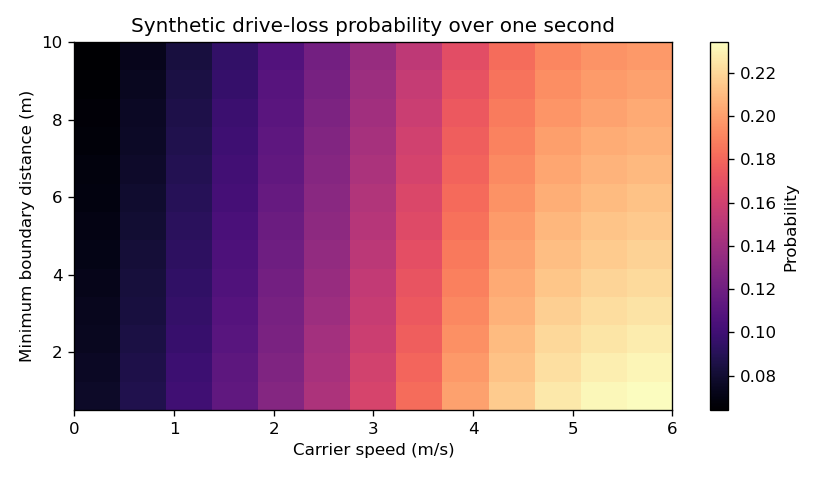

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.model.solver_intensity import integrate_loss_prob

def risk(speed, boundary_distance):
    # Synthetic geometry: two defenders, fixed positions and velocities.
    carrier = np.array([-52.5 + boundary_distance, 0.0])
    defenders = carrier[None, :] + np.array([[3.5, 0.0], [0.0, 5.0]])
    velocities = np.zeros_like(defenders)
    carrier_v = np.array([[speed, 0.0]])
    probs = integrate_loss_prob(defenders, velocities, carrier, carrier_v[0],
        delta_t=1.0, lambda_0=0.36, beta_v=0.09, beta_B=-0.02,
        s=0.43, v_max=7.0, a_max=7.0, dt=0.04)
    return float(np.asarray(probs).sum())
speeds = np.linspace(0, 6, 13)
distances = np.linspace(0.5, 10, 13)
Z = np.array([[risk(v, d) for v in speeds] for d in distances])
fig, ax = plt.subplots(figsize=(7, 4))
image=ax.imshow(Z, origin="lower", aspect="auto", extent=[speeds.min(), speeds.max(), distances.min(), distances.max()], cmap="magma")
ax.set(xlabel="Carrier speed (m/s)", ylabel="Minimum boundary distance (m)", title="Synthetic drive-loss probability over one second")
fig.colorbar(image, ax=ax, label="Probability")
fig.tight_layout()
out=Path("figures/vignette_01_drive_risk.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
plt.show()

### Scope, likelihood and limitations

The short-horizon carrier path is fixed as $x(t)=x_0+vt$. Every defender contributes through its arrival gate, so defensive density already affects the total hazard; boundary distance is recalculated along the path. Carrier speed is a parsimonious proxy for ball-control difficulty. Pose and foot-level control are unavailable in this model. Additional pair geometry, such as closing speed, remains a hypothesis to test after checking the functional form of the tackle rate. **design choice**

The training benchmark uses a fixed one-second Bernoulli target: every loss, including an early loss, contributes $1-S(1)$; a complete success contributes $S(1)$. Short non-loss tails and individual possessions ending in a shot are excluded from training; all usable checkpoints remain available for frame prediction. The previous interval/censoring likelihood is a separate timing experiment. Failed passes are outside the carry-loss target. Segments from the same possession share context, so they do not imply independent samples for uncertainty estimation. **design choice**

The reference defender speed cap is 7 m/s; sensitivity to this effective motion parameter should be assessed separately from tackle-rate extensions. The fitted arrival dispersion near 0.42 s is consistent in magnitude with Spearman's estimate, but it does not independently validate the cap: dispersion, arrival times and tackle rate can compensate in fitting [@spearman2017]. The implemented arrival gate follows the same probabilistic construction, with the linear/turn-time approximation described above. **design choice**

Unexplained outcomes may reflect ordinary stochastic variation, tracking/event noise or model misspecification. They do not by themselves demonstrate missing cognitive effects. Intentions, anticipation, body orientation and technical ability remain possible future directions; some may already be reflected by current motion over a short horizon. The benchmark will compare rate shapes and geometric extensions on identical match splits and exposures before accepting added complexity. **design choice**

Training computes log survival directly from the same frozen-step total hazards as the cause solver. Interval-event log probability uses log S(l) + log(-expm1(-(Lambda(u)-Lambda(l)))), avoiding cancellation and the previous 1e-7 probability floor. Synthetic extreme and tiny hazards test this calculation; they are not claims about rates fitted on the real data. Explicit Euler retains the archived approximation. **own derivation**


## Use the package on a selected frame

This standalone example initializes one match, selects a team possession and a usable tracking frame, and calls the public API for this task. The match and xT inputs are **synthetic**. Small grids make the example quick and change the model inputs; use the research defaults for analysis. Replace the demo initializer with `PRESS.from_skillcorner(...)` from the [match guide](../../usage.qmd) to use processed local files.

The pitch view below uses the package plotting function and the computed values for frame 5, inside an action interval rather than at its start. It shows defender-specific tackle probabilities and total carry-loss probability. Candidate fields use a coarse demonstration grid; the synthetic fixture and grid are not a benchmark.


frame: 5
{'Individual tackle probabilities': Array([3.1424938e-16, 5.7813129e-12, 2.1161579e-11, 4.7424434e-12,
       1.2736632e-13, 3.3167248e-06, 7.3750278e-05, 2.1866701e-06,
       3.7252756e-09, 3.8009444e-03, 1.1821593e-06], dtype=float32), 'Ball drive loss probability': Array(0.00388138, dtype=float32), 'params': {'t_press': 1.0, 'physics_kwargs': {'v_max': 7.0, 'a_max': 7.0, 'lambda_0': 0.36, 'beta_v': 0.09, 'beta_B': -0.02, 's': 0.43, 'integration_method': 'exponential', 'dt': 0.04}}}


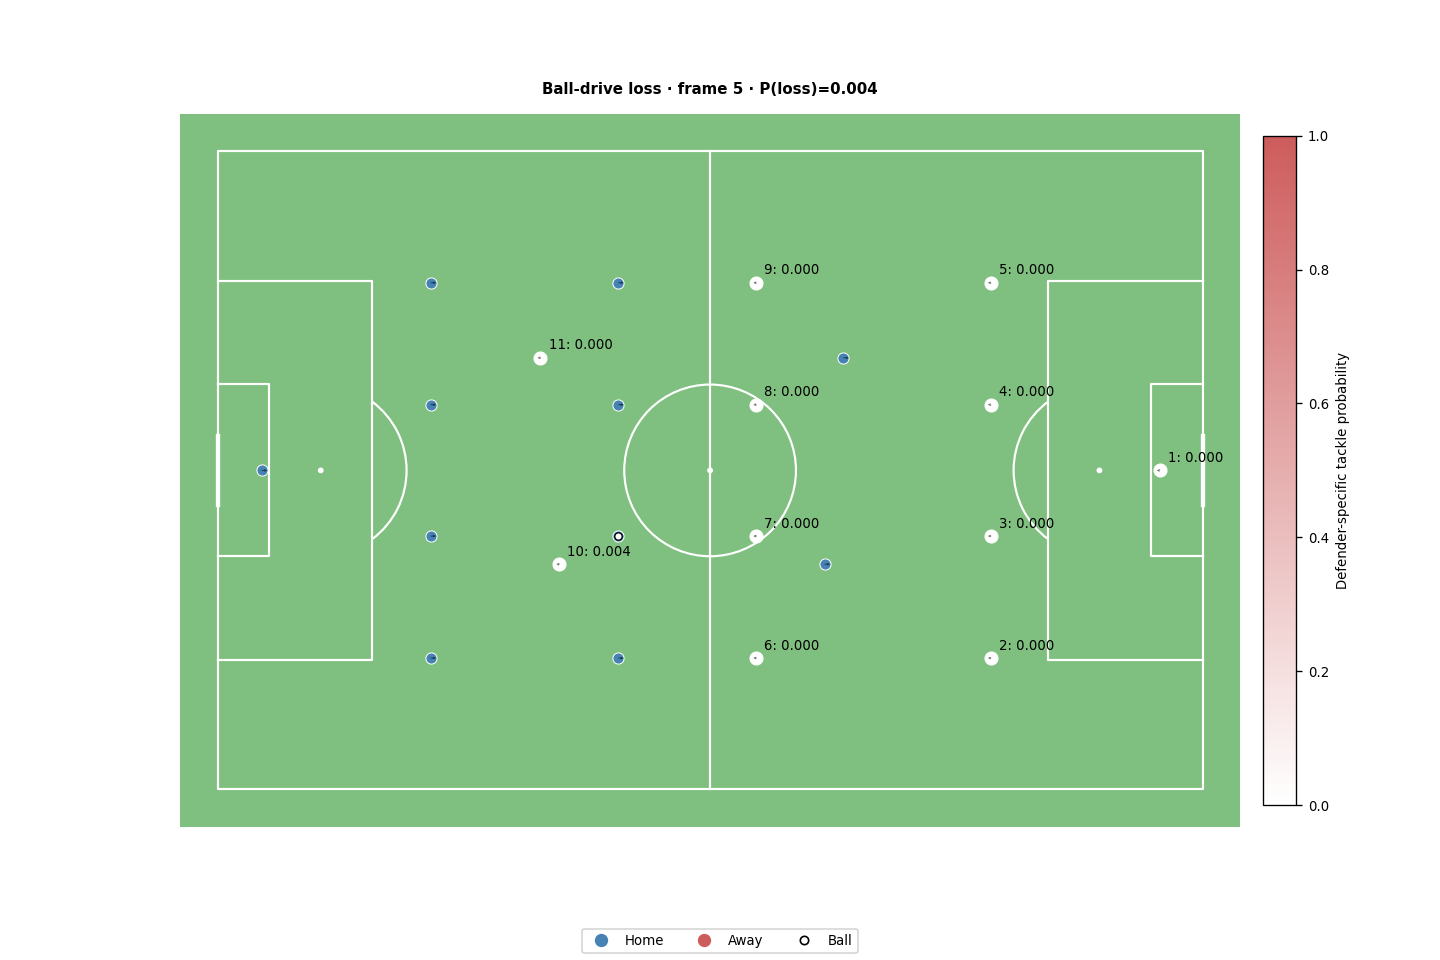

In [6]:
from PRESS import PRESS
from PRESS.datasets import load_demo_match

tracking, possessions, actions, xT_grid = load_demo_match()
model = PRESS(tracking, possessions_data=possessions, actions_data=actions)
possession_id = model.get_possessions().possession_id.iloc[0]
frame_id = int(model.get_frames(possession_id, valid_only=True).frame.iloc[5])
model.compute_ball_drive_loss(frame_id)
print("frame:", frame_id)
print(model.get_ball_drive_result(frame_id))

from PRESS.visualization import plot_pi
plot_pi(model, frame_id)
fig = plt.gcf()
out = Path("figures/vignette_01_drive_pitch.png")
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))


## Covariate meaning and research scope

The [Bekkers pressing framework](https://arxiv.org/html/2501.04712v1) motivates interception-time and logistic reachability. The [dribbling study](https://arxiv.org/html/2506.22503v1) motivates investigating speed and lateral proximity; its maximum episode speed is different from the carrier's current speed, and its sideline distance is different from the minimum over all four pitch boundaries used here. The rate form is a project hypothesis to benchmark, not a fitted equation copied from that study.

The turning penalty speed*angle/a_max follows a constant-speed centripetal-turn approximation, with radians and a_max in m/s². It is added as a realignment time without simulating the curved displacement. This accepted approximation remains separate from the integration-method change.